# 02 · Limpieza SICODIS: regalías que **recibe** Acacías (2013-2026)

**Proyecto:** ¿Acacías vive del petróleo? Regalías vs. desarrollo
**Fuente:** DNP, SICODIS (Sistema General de Regalías).
- *SGR Resumen/Detalle de PBC vs Recaudo – Asignaciones Directas* (carpeta `data/sicodis`), bienios 2013-2014 a 2025-2026. Corte de recaudo: 31/10/2026.
- *SGR Resumen Plan de Recursos* (carpeta `data/sgr plan de recursos`), vigencias 2013-2022 a 2025-2034.

**Descarga:** 24/11/2026

**Conceptos clave**
- **Asignaciones Directas:** la parte de las regalías que va directo a los municipios y departamentos productores. Desde 2021 se dividen en 20% y 5% anticipadas.
- **PBC (Plan Bienal de Caja):** lo que se *proyectaba* recibir mes a mes.
- **Recaudo:** lo que *efectivamente llegó*.
- **Plan de Recursos:** proyección a 10 años del total asignado.

> La carpeta `data/sgr recaudo directa` tiene **los mismos 7 reportes** que `data/sicodis` (mismos bienios, misma entidad), descargados dos veces. Este notebook usa solo `data/sicodis`.

In [1]:
import glob
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.0f}".format)

RAW_RECAUDO = Path("../data/sicodis")
RAW_PLAN = Path("../data/sgr plan de recursos")
OUT = Path("../data processed")
OUT.mkdir(exist_ok=True)

COD_ACACIAS = "50006"

## 1. Recaudo de Asignaciones Directas

Cada Excel tiene dos hojas:
- **Datos PBC Recaudo:** resumen mensual solo de Acacías.
- **Datos PBC Recaudo Detalle:** lo mismo pero para **todas las entidades del país** (unas 28.000 filas). Usamos esta, porque trae el código DANE y permite comparar municipios.

Problemas de formato que hay que resolver:
- El encabezado está en **dos filas** (fuente arriba, PBC/Recaudo abajo) y empieza en la fila 22.
- Hasta 2019-2020 las columnas son `Minería` / `Hidrocarburos`. Desde 2021-2022 se separan en **20%** y **5%**.
- Cada bienio trae una fila de ajuste por decreto (por ejemplo *Decreto 722 de 2015*) que no es un mes.
- El mes viene como texto en español (`"Enero 2013"`).

In [2]:
MESES = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6, "julio": 7,
         "agosto": 8, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}

def mes_a_fecha(texto):
    m = re.match(r"^\s*([A-Za-zÁÉÍÓÚáéíóú]+)\s+(\d{4})\s*$", str(texto))
    if not m or m.group(1).lower() not in MESES:
        return pd.NaT
    return pd.Timestamp(int(m.group(2)), MESES[m.group(1).lower()], 1)


def leer_detalle_recaudo(ruta):
    raw = pd.read_excel(ruta, sheet_name="Datos PBC Recaudo Detalle", header=None, dtype=str)
    bienio = raw.iloc[8, 1]                               # celda con la vigencia, p. ej. '2013 - 2014'
    fila_enc = raw.index[raw[1] == "Mes"][0]              # fila donde empieza el encabezado

    # Unir las dos filas del encabezado: 'Hidrocarburos 20%' + 'PBC' -> 'Hidrocarburos 20%|PBC'
    arriba = raw.iloc[fila_enc].ffill()
    abajo = raw.iloc[fila_enc + 1]
    columnas = [f"{a}|{b}" if pd.notna(b) else a for a, b in zip(arriba, abajo)]

    df = raw.iloc[fila_enc + 2:].copy()
    df.columns = columnas
    df = df.drop(columns=[c for c in df.columns if pd.isna(c) or c == "nan"])
    df["bienio"] = bienio
    return df

archivos = sorted(glob.glob(str(RAW_RECAUDO / "*.xlsx")))
partes = [leer_detalle_recaudo(f) for f in archivos]
for p in partes:
    print(p["bienio"].iloc[0], p.shape, [c for c in p.columns if "|" in c])

2015 - 2016 (18900, 15) ['Minería|PBC', 'Minería|Recaudo', 'Hidrocarburos|PBC', 'Hidrocarburos|Recaudo']
2017 - 2018 (20004, 15) ['Minería|PBC', 'Minería|Recaudo', 'Hidrocarburos|PBC', 'Hidrocarburos|Recaudo']
2019 - 2020 (18800, 15) ['Minería|PBC', 'Minería|Recaudo', 'Hidrocarburos|PBC', 'Hidrocarburos|Recaudo']
2021 - 2022 (17352, 19) ['Minería 20%|PBC', 'Minería 20%|Recaudo', 'Hidrocarburos 20%|PBC', 'Hidrocarburos 20%|Recaudo', 'Minería 5%|PBC', 'Minería 5%|Recaudo', 'Hidrocarburos 5%|PBC', 'Hidrocarburos 5%|Recaudo']
2023 - 2024 (21168, 19) ['Minería 20%|PBC', 'Minería 20%|Recaudo', 'Hidrocarburos 20%|PBC', 'Hidrocarburos 20%|Recaudo', 'Minería 5%|PBC', 'Minería 5%|Recaudo', 'Hidrocarburos 5%|PBC', 'Hidrocarburos 5%|Recaudo']
2025 - 2026 (28664, 19) ['Minería 20%|PBC', 'Minería 20%|Recaudo', 'Hidrocarburos 20%|PBC', 'Hidrocarburos 20%|Recaudo', 'Minería 5%|PBC', 'Minería 5%|Recaudo', 'Hidrocarburos 5%|PBC', 'Hidrocarburos 5%|Recaudo']
2013 - 2014 (17776, 15) ['Minería|PBC', 'Miner

In [3]:
# Pasar a formato largo: una fila por entidad, mes, fuente y concepto (PBC o Recaudo)
id_cols = ["Mes", "Región", "Cod Depto", "Departamento", "Código DANE", "Entidad",
           "Tipo", "Productor", "PDET", "Capital", "bienio"]

largo = pd.concat(
    [p.melt(id_vars=id_cols, var_name="columna", value_name="valor") for p in partes],
    ignore_index=True,
)
largo[["fuente", "concepto"]] = largo["columna"].str.split("|", expand=True)
largo["porcentaje"] = largo["fuente"].str.extract(r"(\d+%)")[0].fillna("Total")
largo["fuente"] = largo["fuente"].str.replace(r"\s*\d+%", "", regex=True).str.strip()
largo["valor"] = pd.to_numeric(largo["valor"], errors="coerce").fillna(0)

# Limpiar textos
for c in ["Entidad", "Departamento", "Región", "Tipo", "Productor", "Código DANE"]:
    largo[c] = largo[c].str.strip()

largo["fecha"] = largo["Mes"].map(mes_a_fecha)
largo = largo.drop(columns="columna")
largo.head()

,Mes,Región,Cod Depto,Departamento,Código DANE,Entidad,Tipo,Productor,PDET,Capital,bienio,valor,fuente,concepto,porcentaje,fecha
0,Enero 2015,Región Eje Cafetero,05000,Antioquia,05000,Antioquia,Gobernación,No Productor,No PDET,No,2015 - 2016,"70,465,065",Minería,PBC,Total,2015-01-01
1,Febrero 2015,Región Eje Cafetero,05000,Antioquia,05000,Antioquia,Gobernación,No Productor,No PDET,No,2015 - 2016,"67,580,425",Minería,PBC,Total,2015-02-01
2,Marzo 2015,Región Eje Cafetero,05000,Antioquia,05000,Antioquia,Gobernación,No Productor,No PDET,No,2015 - 2016,"186,725,510",Minería,PBC,Total,2015-03-01
3,Abril 2015,Región Eje Cafetero,05000,Antioquia,05000,Antioquia,Gobernación,No Productor,No PDET,No,2015 - 2016,"56,459,452",Minería,PBC,Total,2015-04-01
4,Mayo 2015,Región Eje Cafetero,05000,Antioquia,05000,Antioquia,Gobernación,No Productor,No PDET,No,2015 - 2016,"67,524,785",Minería,PBC,Total,2015-05-01


### Filas de ajuste por decreto

In [4]:
ajustes = largo[largo["fecha"].isna()]
print("Valores de 'Mes' que no son meses:", ajustes["Mes"].unique())
print()
print("Ajustes para Acacías:")
print(ajustes[ajustes["Código DANE"] == COD_ACACIAS].query("valor != 0")[["bienio", "Mes", "fuente", "porcentaje", "concepto", "valor"]])

Valores de 'Mes' que no son meses: ['Decreto 1103 de 2017' 'Decreto 606 de 2019' 'Decreto 317 de 2021'
 'Decreto 1027 de 2026' 'Decreto 722 de 2015']

Ajustes para Acacías:
             bienio                   Mes         fuente porcentaje concepto  \
11749   2015 - 2016  Decreto 1103 de 2017        Minería      Total      PBC   
49549   2015 - 2016  Decreto 1103 de 2017  Hidrocarburos      Total      PBC   
107926  2017 - 2018   Decreto 606 de 2019        Minería      Total  Recaudo   
127930  2017 - 2018   Decreto 606 de 2019  Hidrocarburos      Total      PBC   
147934  2017 - 2018   Decreto 606 de 2019  Hidrocarburos      Total  Recaudo   
167465  2019 - 2020   Decreto 317 de 2021        Minería      Total      PBC   
205065  2019 - 2020   Decreto 317 de 2021  Hidrocarburos      Total      PBC   
814864  2013 - 2014   Decreto 722 de 2015  Hidrocarburos      Total      PBC   

                 valor  
11749       -3,638,580  
49549  -13,573,151,226  
107926      -6,329,552  
127930

Estas filas corrigen el **PBC** (lo proyectado) al cierre de cada bienio. No son plata recibida en un mes, así que se dejan **fuera de la serie mensual** y se guardan aparte.

In [5]:
mensual = largo[largo["fecha"].notna()].copy()
mensual["anio"] = mensual["fecha"].dt.year

# Tabla ancha: una fila por entidad y mes, con PBC y Recaudo de hidrocarburos y minería
recaudo = (
    mensual.pivot_table(index=["fecha", "anio", "Código DANE", "Entidad", "Departamento", "Tipo", "Productor"],
                        columns=["fuente", "concepto"], values="valor", aggfunc="sum", fill_value=0)
)
recaudo.columns = [f"{f.lower()}_{c.lower()}" for f, c in recaudo.columns]
recaudo = recaudo.reset_index().rename(columns={"Código DANE": "cod_dane", "Entidad": "entidad",
                                                 "Departamento": "departamento", "Tipo": "tipo",
                                                 "Productor": "productor"})
recaudo["total_recaudo"] = recaudo["hidrocarburos_recaudo"] + recaudo["minería_recaudo"]
recaudo["total_pbc"] = recaudo["hidrocarburos_pbc"] + recaudo["minería_pbc"]

print(recaudo.shape)
print("Meses por año:", recaudo.groupby("anio")["fecha"].nunique().to_dict())

(139056, 13)
Meses por año: {2013: 12, 2014: 12, 2015: 12, 2016: 12, 2017: 12, 2018: 12, 2019: 12, 2020: 12, 2021: 12, 2022: 12, 2023: 12, 2024: 12, 2025: 12, 2026: 12}


**Observación:** la serie va de enero de 2013 a diciembre de 2026, pero el corte de recaudo es **31 de octubre de 2026**. Noviembre y diciembre de 2026 solo traen PBC y su recaudo sale en cero.

## 2. Acacías

In [6]:
acacias = recaudo[recaudo["cod_dane"] == COD_ACACIAS].sort_values("fecha")
corte = pd.Timestamp("2026-10-01")
acacias = acacias[acacias["fecha"] <= corte]

acacias_anual = acacias.groupby("anio")[["hidrocarburos_pbc", "hidrocarburos_recaudo", "minería_recaudo",
                                         "total_pbc", "total_recaudo"]].sum()
acacias_anual["meses"] = acacias.groupby("anio")["fecha"].nunique()
acacias_anual["cumplimiento_pbc_pct"] = 100 * acacias_anual["total_recaudo"] / acacias_anual["total_pbc"]
acacias_anual

,hidrocarburos_pbc,hidrocarburos_recaudo,minería_recaudo,total_pbc,total_recaudo,meses,cumplimiento_pbc_pct
anio,,,,,,,
2013,"16,755,564,504","13,546,865,155","4,170,866","16,755,564,504","13,551,036,021",12,81
2014,"11,902,042,539","13,508,561,649","12,812,257","11,902,042,539","13,521,373,906",12,114
2015,"12,073,224,465","9,821,671,137","11,021,142","12,076,771,245","9,832,692,279",12,81
2016,"14,661,377,814","3,324,515,726","7,784,261","14,665,010,826","3,332,299,987",12,23
2017,"5,831,441,534","8,063,649,075","9,739,159","5,836,486,834","8,073,388,233",12,138
2018,"7,364,199,820","11,757,731,472","9,203,238","7,369,085,737","11,766,934,710",12,160
2019,"10,186,952,905","10,718,862,445","15,346,706","10,194,023,503","10,734,209,151",12,105
2020,"11,811,576,935","5,208,137,346","10,948,872","11,818,638,078","5,219,086,218",12,44
2021,"41,512,895,954","45,674,937,885","44,051,025","41,530,145,270","45,718,988,911",12,110


### Validación

El total del bienio 2013-2014 debe coincidir con la fila *TOTAL* de la hoja resumen de Acacías en el Excel original: **27.055.426.804 pesos** de recaudo de hidrocarburos.

In [7]:
calc = acacias.loc[acacias["anio"].isin([2013, 2014]), "hidrocarburos_recaudo"].sum()
print(f"Recaudo hidrocarburos Acacías 2013-2014 calculado: {calc:,.0f}  (Excel: 27,055,426,804)")

Recaudo hidrocarburos Acacías 2013-2014 calculado: 27,055,426,804  (Excel: 27,055,426,804)


## 3. Plan de Recursos (lo planeado)

In [8]:
def leer_plan_resumen(ruta):
    raw = pd.read_excel(ruta, sheet_name="Datos Plan Recursos", header=None)
    vigencia = raw.iloc[8, 1]
    fila_enc = raw.index[raw[1] == "Concepto"][0]
    tabla = raw.iloc[fila_enc + 1:, 1:].dropna(how="all")
    tabla.columns = ["concepto"] + [int(a) for a in raw.iloc[fila_enc, 2:].dropna()]
    tabla = tabla.dropna(subset=["concepto"])
    tabla["vigencia"] = vigencia
    return tabla.melt(id_vars=["concepto", "vigencia"], var_name="anio", value_name="valor")

plan = pd.concat([leer_plan_resumen(f) for f in sorted(glob.glob(str(RAW_PLAN / "*.xlsx")))], ignore_index=True)
plan["anio_inicio"] = plan["vigencia"].str[:4].astype(int)
plan["concepto"] = plan["concepto"].str.strip()
print(plan["concepto"].unique())
print(plan["vigencia"].unique())

['INVERSIÓN' 'Asignaciones Directas' 'A. Directas'
 'A. Directas anticipadas' 'AHORRO' 'FONPET' 'Total' 'FAE'
 'FDR Compensación' 'FCR 40%']
['2023 - 2032' '2021 - 2030' '2019 - 2028' '2017 - 2026' '2015 - 2024'
 '2013 - 2022' '2025 - 2034']


Cada plan proyecta 10 años, y se rehace cada dos años. Para armar una sola serie de **lo planeado** se toman solo los **dos primeros años** de cada plan, que son los del bienio vigente.

In [9]:
plan_bienio = plan[(plan["anio"] - plan["anio_inicio"] < 2) & (plan["concepto"] == "Total")]
plan_anual = plan_bienio.set_index("anio")["valor"].astype(float).rename("plan_recursos_total")
plan_anual

anio
2023   96,409,206,894
2024   98,518,586,828
2021   41,530,041,582
2022   54,426,708,551
2019   10,370,766,672
2020   12,007,917,003
2017    6,039,336,991
2018    7,600,844,867
2015   12,730,734,031
2016   14,997,263,097
2013   18,328,025,664
2014   17,801,195,444
2025   65,352,078,903
2026   68,191,047,150
Name: plan_recursos_total, dtype: float64

## 4. Generado vs. recibido

Se une con la salida del notebook 01 (**regalías generadas** por la producción de Acacías, según la ANH).

⚠️ No son conceptos idénticos. La ANH liquida todas las regalías del petróleo extraído en el municipio; SICODIS muestra solo las **Asignaciones Directas** que le tocan a la alcaldía. El resto se va a fondos regionales, al departamento, a ahorro, a ciencia y tecnología, etc. Justo esa diferencia es la que queremos mostrar.

In [10]:
anh = pd.read_csv(OUT / "anh_municipios_anual.csv")
generado = anh[anh["municipio"] == "ACACIAS"].set_index("anio")["regalias_cop"].rename("regalias_generadas_anh")

comparacion = (
    pd.concat([generado, plan_anual, acacias_anual["total_recaudo"].rename("asignaciones_directas_recibidas")], axis=1)
    .loc[2013:2026]
)
comparacion["recibido_por_cada_100_generados"] = 100 * comparacion["asignaciones_directas_recibidas"] / comparacion["regalias_generadas_anh"]
comparacion

,regalias_generadas_anh,plan_recursos_total,asignaciones_directas_recibidas,recibido_por_cada_100_generados
anio,,,,
2013,"358,966,043,561","18,328,025,664","13,551,036,021",4
2014,"368,399,945,030","17,801,195,444","13,521,373,906",4
2015,"226,273,480,580","12,730,734,031","9,832,692,279",4
2016,"186,867,905,711","14,997,263,097","3,332,299,987",2
2017,"321,547,796,606","6,039,336,991","8,073,388,233",3
2018,"454,255,327,869","7,600,844,867","11,766,934,710",3
2019,"492,946,164,063","10,370,766,672","10,734,209,151",2
2020,"204,103,249,775","12,007,917,003","5,219,086,218",3
2021,"600,245,682,921","41,530,041,582","45,718,988,911",8


> **2026:** la ANH llega hasta junio y SICODIS hasta octubre, así que ese año no es comparable. Se excluye del gráfico.

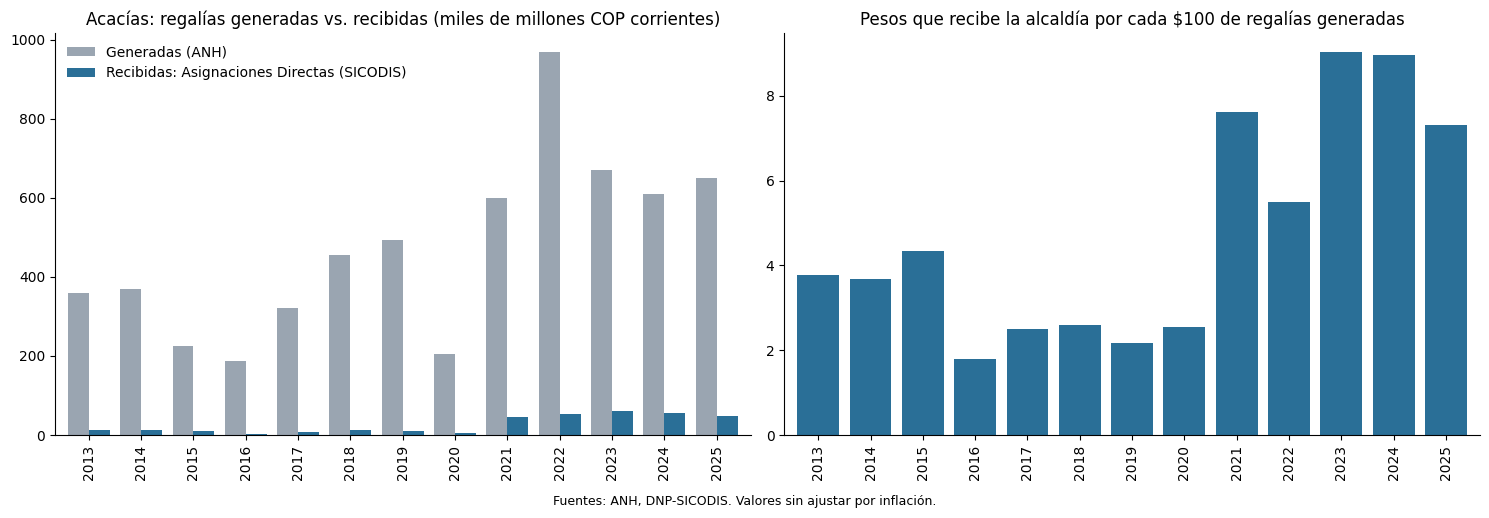

In [11]:
g = comparacion.loc[2013:2025] / 1e9

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

g[["regalias_generadas_anh", "asignaciones_directas_recibidas"]].plot(
    kind="bar", ax=ax[0], width=0.8, color=["#9aa5b1", "#2a6f97"])
ax[0].set_title("Acacías: regalías generadas vs. recibidas (miles de millones COP corrientes)")
ax[0].legend(["Generadas (ANH)", "Recibidas: Asignaciones Directas (SICODIS)"], frameon=False)
ax[0].set_xlabel("")

comparacion.loc[2013:2025, "recibido_por_cada_100_generados"].plot(kind="bar", ax=ax[1], color="#2a6f97", width=0.8)
ax[1].set_title("Pesos que recibe la alcaldía por cada $100 de regalías generadas")
ax[1].set_xlabel("")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.02, "Fuentes: ANH, DNP-SICODIS. Valores sin ajustar por inflación.", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura rápida:** la alcaldía recibe entre **2 y 9 pesos por cada 100** de regalías que genera su petróleo. El salto de 2021 coincide con la entrada en vigor del nuevo régimen del SGR (Ley 2056 de 2020), que subió la porción de Asignaciones Directas y creó la división 20% + 5%. Vale la pena confirmarlo y citarlo en el análisis final.

## 5. Comparación con otros municipios productores

In [12]:
municipios_anual = (
    recaudo[(recaudo["tipo"] == "Municipio") & (recaudo["fecha"] <= corte)]
    .groupby(["cod_dane", "entidad", "departamento", "productor", "anio"], as_index=False)[["total_pbc", "total_recaudo"]]
    .sum()
)

top_2025 = (municipios_anual[municipios_anual["anio"] == 2025]
            .nlargest(10, "total_recaudo")[["entidad", "departamento", "total_recaudo"]]
            .reset_index(drop=True))
top_2025.index += 1
top_2025

,entidad,departamento,total_recaudo
1,Puerto Gaitán,Meta,"138,118,910,645"
2,Becerril,Cesar,"92,594,878,461"
3,Barrancas,La Guajira,"68,937,748,542"
4,Cartagena,Bolívar,"62,580,501,333"
5,Agustín Codazzi,Cesar,"51,972,813,466"
6,Acacías,Meta,"47,522,408,256"
7,Aguazul,Casanare,"46,125,278,731"
8,Ciénaga,Magdalena,"36,064,017,852"
9,Barrancabermeja,Santander,"34,972,828,883"
10,Castilla la Nueva,Meta,"33,611,108,866"


## 6. Exportar

In [13]:
recaudo.to_csv(OUT / "sicodis_directas_mensual_nacional.csv", index=False, encoding="utf-8-sig")
municipios_anual.to_csv(OUT / "sicodis_municipios_anual.csv", index=False, encoding="utf-8-sig")
acacias.to_csv(OUT / "sicodis_acacias_mensual.csv", index=False, encoding="utf-8-sig")
plan.to_csv(OUT / "sicodis_plan_recursos_acacias.csv", index=False, encoding="utf-8-sig")
ajustes.to_csv(OUT / "sicodis_ajustes_decretos.csv", index=False, encoding="utf-8-sig")
comparacion.to_csv(OUT / "acacias_generado_vs_recibido.csv", encoding="utf-8-sig")
print("Listo:", sorted(p.name for p in OUT.glob("sicodis_*.csv")) + ["acacias_generado_vs_recibido.csv"])

Listo: ['sicodis_acacias_mensual.csv', 'sicodis_ajustes_decretos.csv', 'sicodis_directas_mensual_nacional.csv', 'sicodis_municipios_anual.csv', 'sicodis_plan_recursos_acacias.csv', 'acacias_generado_vs_recibido.csv']


## Notas para el análisis

- **Cifras en pesos corrientes:** falta deflactar con el IPC.
- **Asignaciones Directas no es todo lo que recibe Acacías del SGR.** También puede beneficiarse de proyectos financiados con asignaciones regionales o departamentales. Eso se ve en MapaInversiones (notebook de proyectos).
- **El recaudo es en caja:** un mes con recaudo cero no significa que no hubo producción; puede ser un rezago en los giros.